# Workshop 2 — Red neuronal profunda desde cero: resistencia del concreto

**Curso:** ST1613 Applied Machine Learning — EAFIT
**Competencia:** [Concrete Strength Regression (Kaggle)](https://www.kaggle.com/competitions/concrete-strength-regression)
**Framework:** PyTorch

**Objetivo:** construir, entrenar y evaluar una red neuronal *fully connected* (MLP) implementada desde cero en PyTorch para predecir la **resistencia a la compresión del concreto** (`csMPa`, en MPa) a partir de su composición y edad. La métrica oficial de la competencia es el **MSE** (menor es mejor).

## Índice

0. Setup
1. Parte 1 — EDA de reconocimiento
2. Parte 2 — Preprocesamiento
3. Parte 3 — `Dataset` y `DataLoader`
4. Parte 4 — Arquitectura de la red
5. Parte 5 — Entrenamiento y validación
6. Parte 6 — Experimentación
7. Parte 7 — Predicción y submission en Kaggle
8. Conclusiones

## 0. Setup

Importamos las librerías, fijamos semillas para que los resultados sean reproducibles y definimos el `device`. Con 721 filas la CPU es suficiente, pero el código usa `cuda` si está disponible.

In [1]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

DATA_DIR = "../data"
FIG_DIR = "../reports/figures"
SUB_DIR = "../submissions"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)

ID_COL, TARGET = "Row ID", "csMPa"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)

PyTorch: 2.11.0+cpu | device: cpu


## 1. Parte 1 — EDA de reconocimiento

Antes de modelar exploramos los datos para entender su estructura y justificar las decisiones de preprocesamiento.

### 1.1 Dimensiones, tipos de datos y primeras filas

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
print("Columnas:", list(train.columns))

train: (721, 10) | test: (309, 9) | sample_submission: (10, 2)
Columnas: ['Row ID', 'cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age', 'csMPa']


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            721 non-null    int64  
 1   cement            721 non-null    float64
 2   slag              721 non-null    float64
 3   flyash            721 non-null    float64
 4   water             721 non-null    float64
 5   superplasticizer  721 non-null    float64
 6   coarseaggregate   721 non-null    float64
 7   fineaggregate     721 non-null    float64
 8   age               721 non-null    int64  
 9   csMPa             721 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 56.5 KB


In [4]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID            309 non-null    int64  
 1   cement            309 non-null    float64
 2   slag              309 non-null    float64
 3   flyash            309 non-null    float64
 4   water             309 non-null    float64
 5   superplasticizer  309 non-null    float64
 6   coarseaggregate   309 non-null    float64
 7   fineaggregate     309 non-null    float64
 8   age               309 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 21.9 KB


In [5]:
train.head()

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,0,184.0,86.0,190.0,213.0,6.0,923.0,623.0,28,22.93
1,1,313.3,145.0,0.0,178.5,8.0,1001.9,688.7,28,41.05
2,2,387.0,20.0,94.0,157.0,13.9,938.0,845.0,7,45.90
3,3,162.0,214.0,164.0,202.0,10.0,820.0,680.0,28,30.65
4,4,252.3,0.0,98.8,146.3,14.2,987.8,889.0,14,42.29


In [6]:
test.head()

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age
0,721,167.4,129.9,128.6,175.5,7.8,1006.3,746.6,14
1,722,255.5,170.3,0.0,185.7,0.0,1026.6,724.3,28
2,723,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,3
3,724,318.8,212.5,0.0,155.7,14.3,852.1,880.4,28
4,725,218.9,0.0,124.1,158.5,11.3,1078.7,794.9,56


In [7]:
sample_sub.head(10)

,Row ID,csMPa
0,136,3.0
1,141,4.0
2,164,5.0
3,262,6.0
4,247,7.0
5,51,8.0
6,10,9.0
7,225,10.0
8,2,11.0
9,158,12.0


**Observaciones:**
- `train` tiene **721 filas × 10 columnas** (`Row ID`, 8 predictores y el target `csMPa`) y `test` tiene **309 filas × 9 columnas** (sin target). Los nombres reales difieren de los del enunciado: `slag`, `flyash`, `superplasticizer`, `coarseaggregate`, `fineaggregate`, `age`, `csMPa`.
- Todos los predictores son `float64`, salvo `age` (`int64`).
- `sample_submission.csv` **solo trae 10 filas ilustrativas**, y sus `Row ID` son del rango de train. La submission real debe tener una fila por cada registro de `test.csv` (309 filas, `Row ID` 721–1029) con las columnas `Row ID, csMPa`.

### 1.2 Estadísticas descriptivas

In [8]:
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
train[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
cement,721.0,280.63,103.11,102.00,194.70,273.00,359.00,540.0
slag,721.0,74.74,85.70,0.00,0.00,24.00,142.80,359.4
flyash,721.0,54.87,63.33,0.00,0.00,0.00,118.20,200.0
water,721.0,181.03,21.57,121.80,164.90,184.00,192.00,247.0
superplasticizer,721.0,6.50,6.00,0.00,0.00,6.90,10.60,32.2
coarseaggregate,721.0,971.40,76.52,801.00,932.00,967.00,1028.40,1134.3
fineaggregate,721.0,775.13,78.89,594.00,734.00,780.00,825.00,992.6
age,721.0,44.95,60.43,1.00,14.00,28.00,56.00,365.0
csMPa,721.0,36.16,17.20,2.33,23.35,34.57,47.71,82.6


In [9]:
test[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
cement,309.0,282.42,107.85,108.3,190.3,272.8,342.0,540.0
slag,309.0,71.93,87.73,0.0,0.0,17.5,143.0,359.4
flyash,309.0,52.59,65.59,0.0,0.0,0.0,118.3,200.1
water,309.0,182.82,20.82,121.8,168.0,185.7,192.9,246.9
superplasticizer,309.0,5.51,5.87,0.0,0.0,5.8,9.7,32.2
coarseaggregate,309.0,976.46,80.57,801.0,932.0,971.8,1040.0,1145.0
fineaggregate,309.0,769.97,83.13,594.0,728.9,778.0,822.0,945.0
age,309.0,47.32,69.22,1.0,7.0,28.0,56.0,365.0


**Observaciones:**
- Las escalas son muy distintas: `superplasticizer` va de 0 a 32, mientras que `coarseaggregate` va de 801 a 1134 y `fineaggregate` de 594 a 993. Sin escalar, las variables grandes dominarían los gradientes de la red.
- `slag`, `flyash` y `superplasticizer` tienen mínimo 0 y mediana baja o nula: muchas mezclas no usan esos componentes.
- `age` tiene media 45 pero mediana 28 y máximo 365, señal de una cola larga a la derecha.
- El target `csMPa` va de 2.3 a 82.6 MPa (media 36.2, desviación 17.2).
- Las estadísticas de `test` son muy parecidas a las de `train` (lo verificamos formalmente en 1.8).

### 1.3 Valores faltantes y filas duplicadas

In [10]:
missing = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
print("Total faltantes -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
missing.T

Total faltantes -> train: 0 | test: 0


,Row ID,age,cement,coarseaggregate,csMPa,fineaggregate,flyash,slag,superplasticizer,water
train,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
test,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0


In [11]:
# Excluimos Row ID: dos filas con distinto ID pero misma mezcla y resultado son duplicados reales.
dup_exact = train.duplicated(subset=FEATURES + [TARGET]).sum()
dup_feat = train.duplicated(subset=FEATURES).sum()
print(f"Filas duplicadas exactas (features + target): {dup_exact}")
print(f"Filas con features repetidas (sin contar target): {dup_feat}")

# Mezclas repetidas con target distinto: mismo concreto, distinto resultado de laboratorio.
grp = train.groupby(FEATURES)[TARGET].agg(["count", "nunique", "min", "max", "std"])
conflict = grp[(grp["count"] > 1) & (grp["nunique"] > 1)].reset_index()
print(f"Mezclas repetidas con target distinto: {len(conflict)}")
conflict.sort_values("std", ascending=False)

Filas duplicadas exactas (features + target): 16
Filas con features repetidas (sin contar target): 26
Mezclas repetidas con target distinto: 7


,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,count,nunique,min,max,std
2,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,3,2,22.90,55.90,19.05
4,446.0,24.0,79.0,162.0,11.6,967.0,712.0,7,2,2,38.02,52.01,9.89
3,446.0,24.0,79.0,162.0,11.6,967.0,712.0,3,3,3,23.35,35.36,6.51
5,446.0,24.0,79.0,162.0,11.6,967.0,712.0,28,3,3,44.42,57.03,6.31
6,446.0,24.0,79.0,162.0,11.6,967.0,712.0,56,3,3,55.25,61.07,3.14
1,359.0,19.0,141.0,154.0,10.9,942.0,801.0,28,2,2,59.49,62.94,2.44
0,359.0,19.0,141.0,154.0,10.9,942.0,801.0,3,2,2,23.64,25.12,1.05


In [12]:
n_test_in_train = test[FEATURES].merge(train[FEATURES].drop_duplicates(), how="inner").shape[0]
print(f"Filas de test cuyas features aparecen tal cual en train: {n_test_in_train}")
print(f"Duplicados dentro de test: {test.duplicated(subset=FEATURES).sum()}")

Filas de test cuyas features aparecen tal cual en train: 11
Duplicados dentro de test: 4


**Observaciones:**
- **No hay valores faltantes** ni en `train` ni en `test`, como dice la documentación. No hace falta imputar.
- Hay **16 filas duplicadas exactas** (misma mezcla, edad y resistencia) y **26 filas** que repiten una combinación de predictores ya vista. En **7 mezclas repetidas el target es distinto**; la diferencia llega a 33 MPa (22.9 vs 55.9) para la misma mezcla a 7 días. Esto refleja la **variabilidad propia del ensayo de laboratorio**: es ruido irreducible que ningún modelo puede eliminar.
- **Implicación para la validación:** si una misma mezcla queda en entrenamiento y en validación a la vez, la red "la recuerda" y el error de validación sale optimista. En la Parte 2 lo manejaremos agrupando las mezclas idénticas en la partición (`GroupKFold` / split por grupo).
- 11 filas de `test` tienen predictores idénticos a filas de `train`. No las explotamos manualmente: el modelo debe generalizar.

### 1.4 Tipos de variables: numéricas, categóricas y columnas a excluir

In [13]:
num_cols = train[FEATURES].select_dtypes(include="number").columns.tolist()
cat_cols = train[FEATURES].select_dtypes(exclude="number").columns.tolist()
print("Numéricas :", num_cols)
print("Categóricas:", cat_cols if cat_cols else "ninguna")

summary = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "n_unicos": train[FEATURES].nunique(),
    "pct_ceros": (train[FEATURES] == 0).mean().mul(100).round(1),
})
summary

Numéricas : ['cement', 'slag', 'flyash', 'water', 'superplasticizer', 'coarseaggregate', 'fineaggregate', 'age']
Categóricas: ninguna


,dtype,n_unicos,pct_ceros
cement,float64,245,0.0
slag,float64,153,44.7
flyash,float64,131,53.7
water,float64,174,0.0
superplasticizer,float64,105,34.5
coarseaggregate,float64,242,0.0
fineaggregate,float64,259,0.0
age,int64,14,0.0


In [14]:
# Row ID es solo un identificador: comprobamos que no tiene relación con el target.
r, p = stats.pearsonr(train[ID_COL], train[TARGET])
print(f"Correlación Row ID vs {TARGET}: r = {r:.3f} (p = {p:.2f})")

Correlación Row ID vs csMPa: r = -0.019 (p = 0.61)


**Observaciones:**
- Las **8 variables predictoras son numéricas continuas** (cantidades en kg/m³ y edad en días). **No hay variables categóricas, así que no se requiere encoding.**
- `age` solo toma **14 valores distintos**, por lo que podría tratarse como categórica. Sin embargo es una magnitud ordenada (más días → más resistencia), y tratarla como numérica conserva esa relación y permite interpolar edades intermedias. La trataremos como **numérica** (transformada con `log1p`).
- `Row ID` es un identificador secuencial sin relación con el target (r = −0.02, p = 0.61), así que **se excluye de los predictores**. Solo se usa para construir la submission.

### 1.5 Distribución de la variable objetivo

Asimetría (skew): 0.391 | curtosis: -0.445
Límites IQR: [-13.19, 84.25] MPa -> outliers: 0


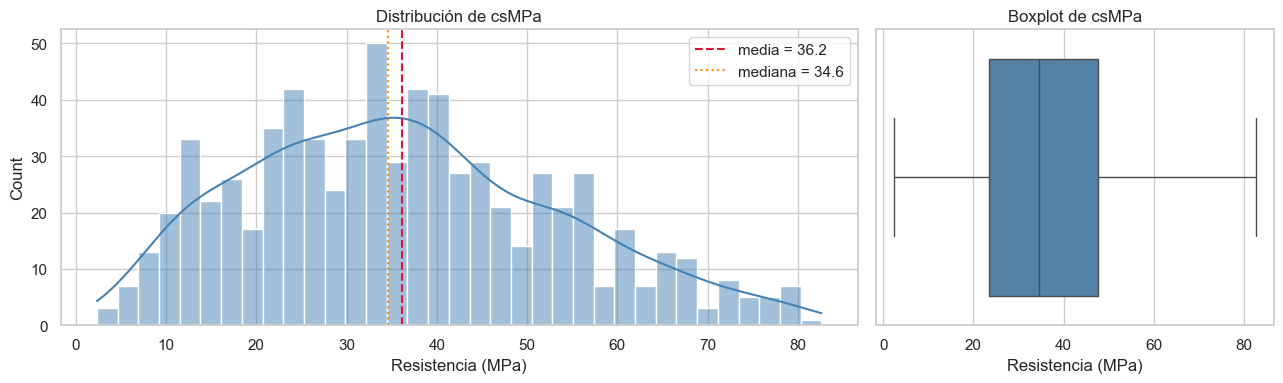

,Row ID,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa


In [15]:
y = train[TARGET]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = train[(y < lo) | (y > hi)]

print(f"Asimetría (skew): {y.skew():.3f} | curtosis: {y.kurt():.3f}")
print(f"Límites IQR: [{lo:.2f}, {hi:.2f}] MPa -> outliers: {len(outliers)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(y, bins=35, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(y.mean(), color="crimson", ls="--", label=f"media = {y.mean():.1f}")
axes[0].axvline(y.median(), color="darkorange", ls=":", label=f"mediana = {y.median():.1f}")
axes[0].set(title="Distribución de csMPa", xlabel="Resistencia (MPa)")
axes[0].legend()
sns.boxplot(x=y, ax=axes[1], color="steelblue")
axes[1].set(title="Boxplot de csMPa", xlabel="Resistencia (MPa)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_target_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

outliers.sort_values(TARGET)

**Observaciones:**
- La distribución de `csMPa` es **unimodal y ligeramente asimétrica a la derecha** (skew = 0.39; media 36.2 > mediana 34.6), con colas más livianas que una normal (curtosis = −0.45).
- Con el criterio IQR **no hay outliers** (límites [−13.2, 84.3] MPa; el máximo es 82.6). No hace falta eliminar ni recortar valores del target.
- La asimetría es leve, así que no transformaremos el target con `log`. Sí lo **estandarizaremos** (`StandardScaler`) para estabilizar el entrenamiento, e invertiremos la transformación antes de calcular métricas y generar la submission.

### 1.6 Distribución de cada predictor

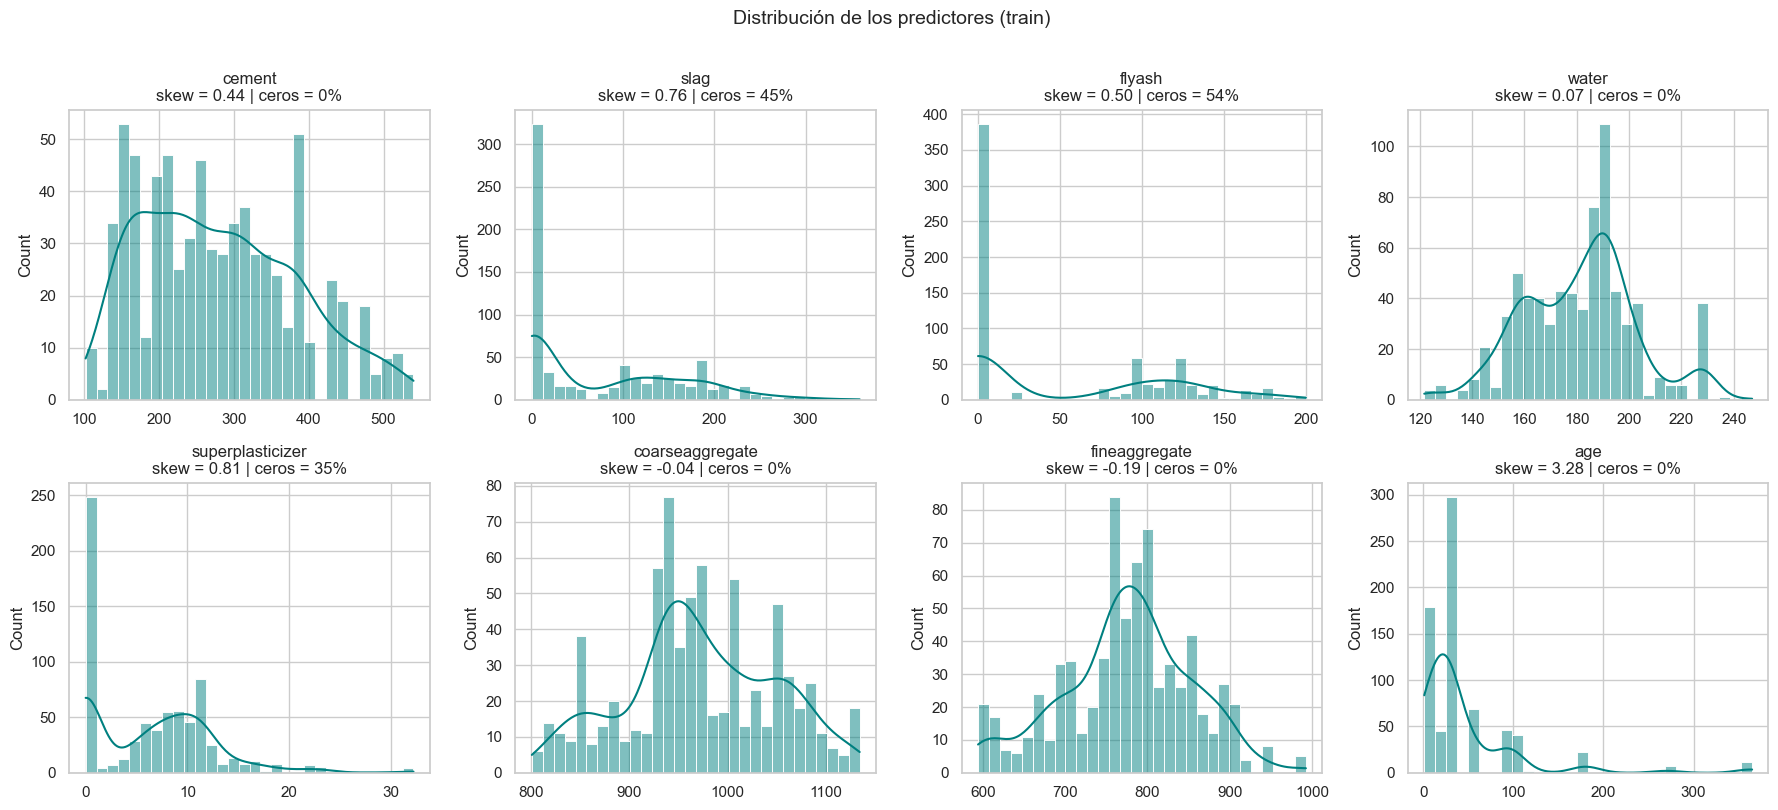

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(train[col], bins=30, kde=True, ax=ax, color="teal")
    ax.set_title(f"{col}\nskew = {train[col].skew():.2f} | ceros = {(train[col] == 0).mean():.0%}")
    ax.set_xlabel("")
plt.suptitle("Distribución de los predictores (train)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_feature_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
skew_zero = pd.DataFrame({
    "skew": train[FEATURES].skew(),
    "pct_ceros": (train[FEATURES] == 0).mean().mul(100),
    "min": train[FEATURES].min(),
    "max": train[FEATURES].max(),
}).sort_values("skew", ascending=False)
skew_zero

,skew,pct_ceros,min,max
age,3.28,0.00,1.0,365.0
superplasticizer,0.81,34.54,0.0,32.2
slag,0.76,44.66,0.0,359.4
flyash,0.50,53.68,0.0,200.0
cement,0.44,0.00,102.0,540.0
water,0.07,0.00,121.8,247.0
coarseaggregate,-0.04,0.00,801.0,1134.3
fineaggregate,-0.19,0.00,594.0,992.6


Valores distintos de age: 14
Top 4 (28, 3, 7, 56 días) concentran el 76% de las filas


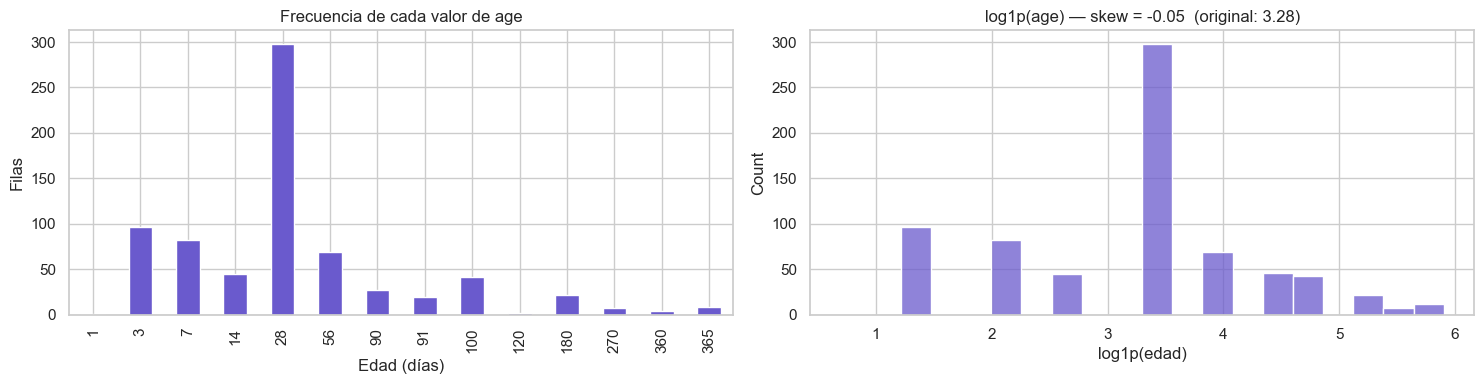

In [18]:
# Age: pocos valores distintos y muy concentrados.
age_counts = train["age"].value_counts().sort_index()
print("Valores distintos de age:", train["age"].nunique())
print(f"Top 4 (28, 3, 7, 56 días) concentran el {train['age'].isin([28, 3, 7, 56]).mean():.0%} de las filas")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
age_counts.plot.bar(ax=axes[0], color="slateblue")
axes[0].set(title="Frecuencia de cada valor de age", xlabel="Edad (días)", ylabel="Filas")
sns.histplot(np.log1p(train["age"]), bins=20, ax=axes[1], color="slateblue")
axes[1].set(title=f"log1p(age) — skew = {np.log1p(train['age']).skew():.2f}  (original: {train['age'].skew():.2f})",
            xlabel="log1p(edad)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_age.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- **Muchos ceros:** `flyash` (54 %), `slag` (45 %) y `superplasticizer` (35 %). Estas variables son una mezcla de "no se usa el componente" (cero) y "cantidad usada" (distribución continua). Por eso crearemos **indicadores binarios de presencia** (`has_slag`, `has_flyash`, `has_sp`).
- **`age` es la variable más asimétrica** (skew = 3.28) y está muy concentrada: 28, 3, 7 y 56 días suman el 76 % de las filas. Con `log1p(age)` la asimetría baja a −0.05, lo que la hace más adecuada como entrada de la red.
- `water`, `coarseaggregate` y `fineaggregate` son aproximadamente simétricas y no requieren transformación más allá del escalamiento.

### 1.7 Correlaciones y relación de cada predictor con el objetivo

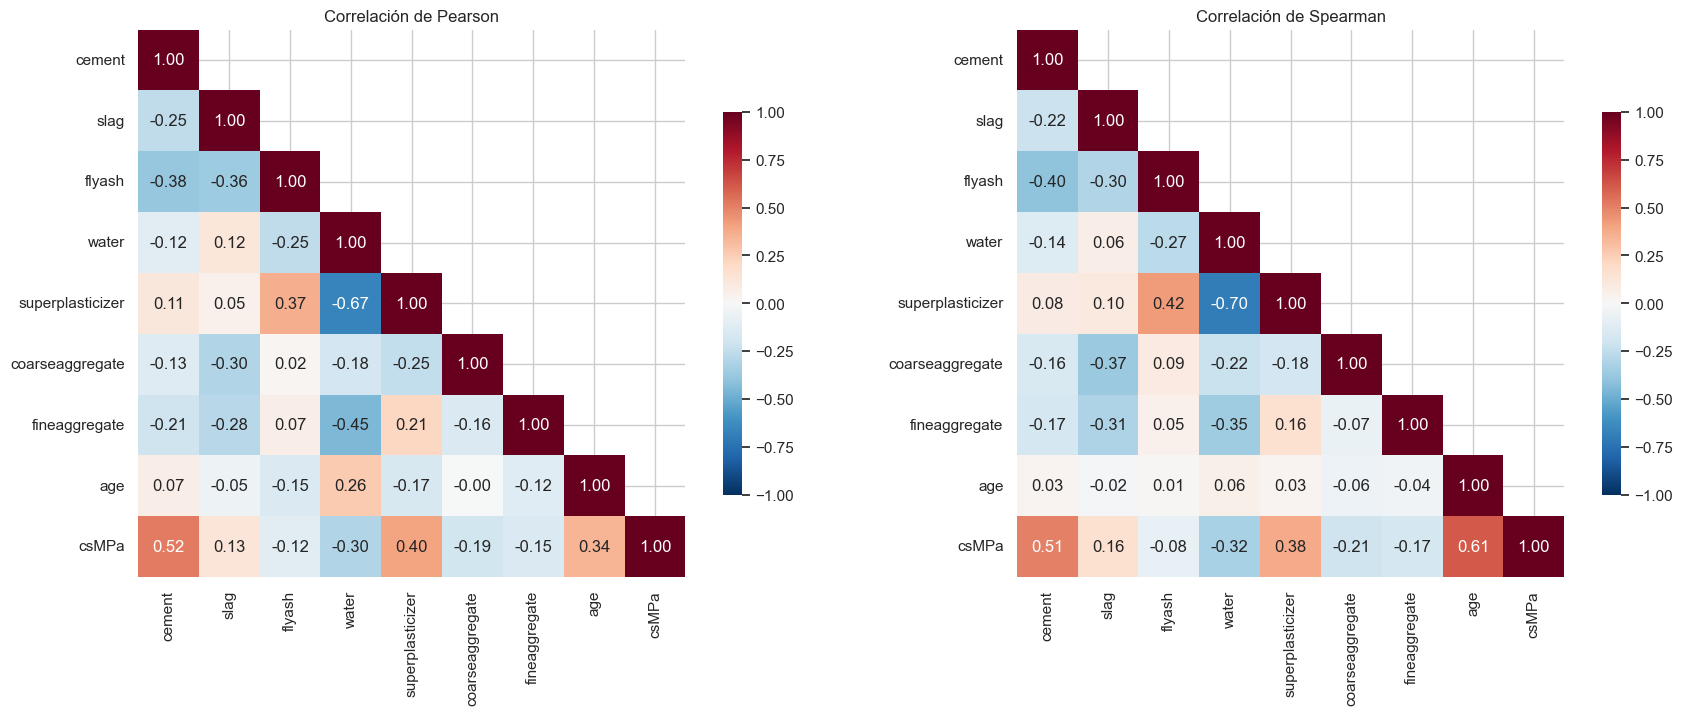

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = train[FEATURES + [TARGET]].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"Correlación de {method.capitalize()}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_correlations.png", dpi=120, bbox_inches="tight")
plt.show()

In [20]:
corr_target = pd.DataFrame({
    "pearson": train[FEATURES].corrwith(train[TARGET]),
    "spearman": train[FEATURES].corrwith(train[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
corr_target

,pearson,spearman
cement,0.52,0.51
superplasticizer,0.40,0.38
age,0.34,0.61
water,-0.30,-0.32
coarseaggregate,-0.19,-0.21
fineaggregate,-0.15,-0.17
slag,0.13,0.16
flyash,-0.12,-0.08


**Observaciones:**
- Los predictores con mayor correlación lineal con la resistencia son `cement` (+0.52), `superplasticizer` (+0.40), `age` (+0.34) y `water` (−0.30). Los agregados, `slag` y `flyash` tienen correlaciones débiles por sí solos.
- Para `age` la correlación de **Spearman (0.61) es mucho mayor que la de Pearson (0.34)**: la relación es **monótona pero no lineal**.
- Entre predictores hay correlaciones moderadas (p. ej. `water` vs `superplasticizer` = −0.67). No es un problema serio para una red neuronal, pero confirma que las variables interactúan.

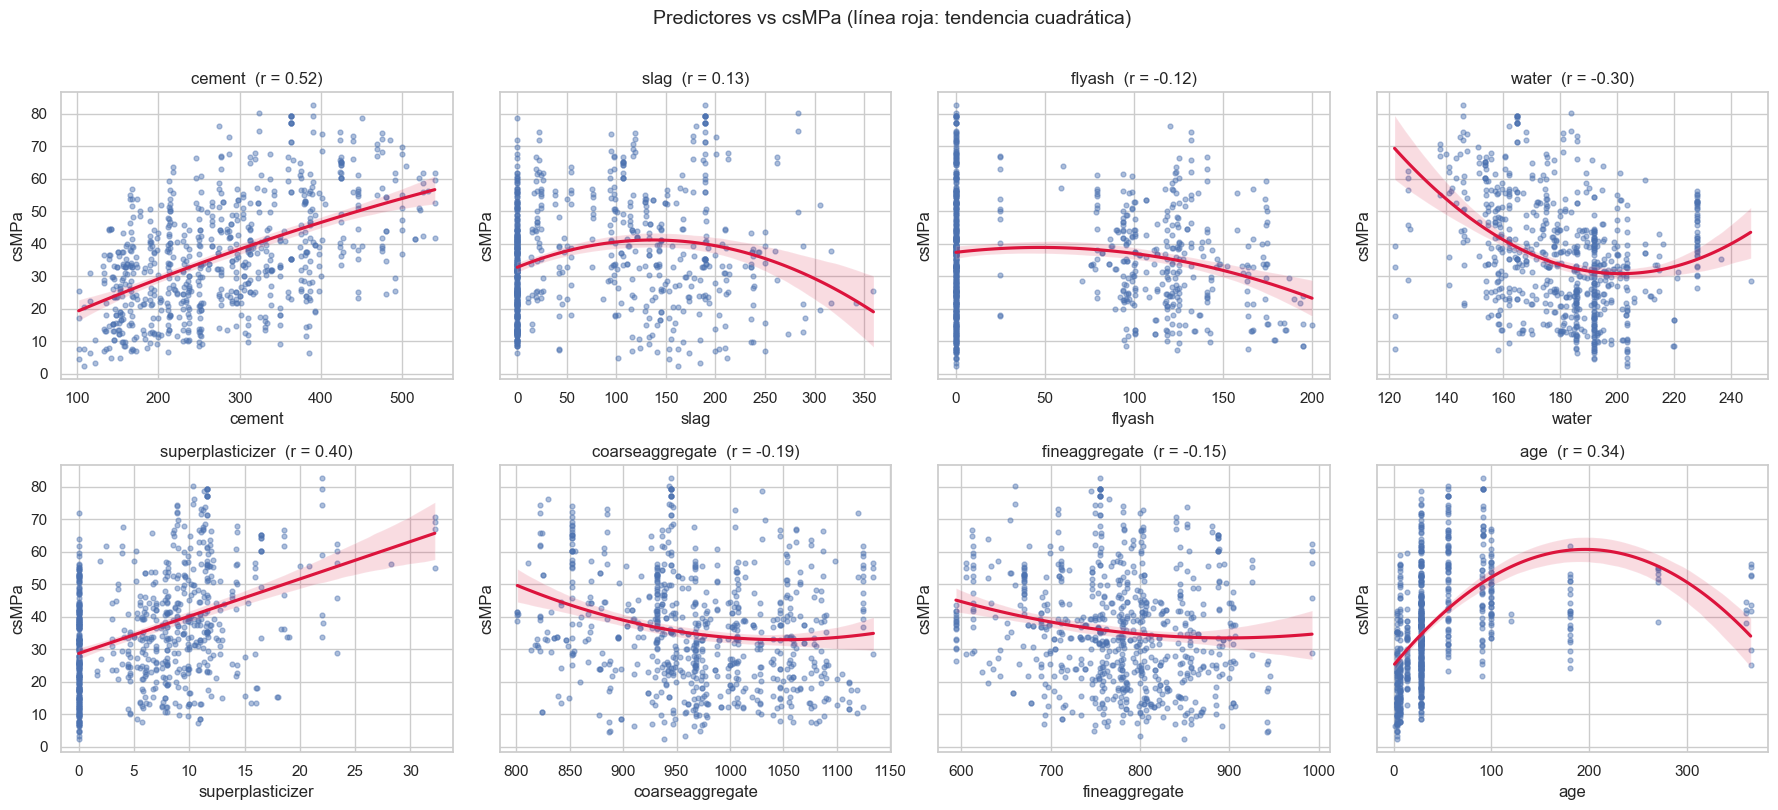

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, col in zip(axes.ravel(), FEATURES):
    sns.regplot(data=train, x=col, y=TARGET, ax=ax, order=2,
                scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
    ax.set_title(f"{col}  (r = {train[col].corr(train[TARGET]):.2f})")
plt.suptitle("Predictores vs csMPa (línea roja: tendencia cuadrática)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_scatter_vs_target.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- Ningún predictor por sí solo explica bien la resistencia: hay mucha dispersión vertical en todos los gráficos. El target depende de **combinaciones** de variables, justo lo que una red neuronal puede modelar.
- `cement` y `superplasticizer` muestran tendencias crecientes claras; `water` una tendencia decreciente.
- En `slag`, `flyash` y `superplasticizer` se ve la columna de puntos en 0 que comentamos antes.
- En `age` la curva cuadrática cae al final, pero es un artefacto del ajuste polinómico con pocos puntos en edades altas. La relación real es creciente y se satura, como se ve en la siguiente figura.

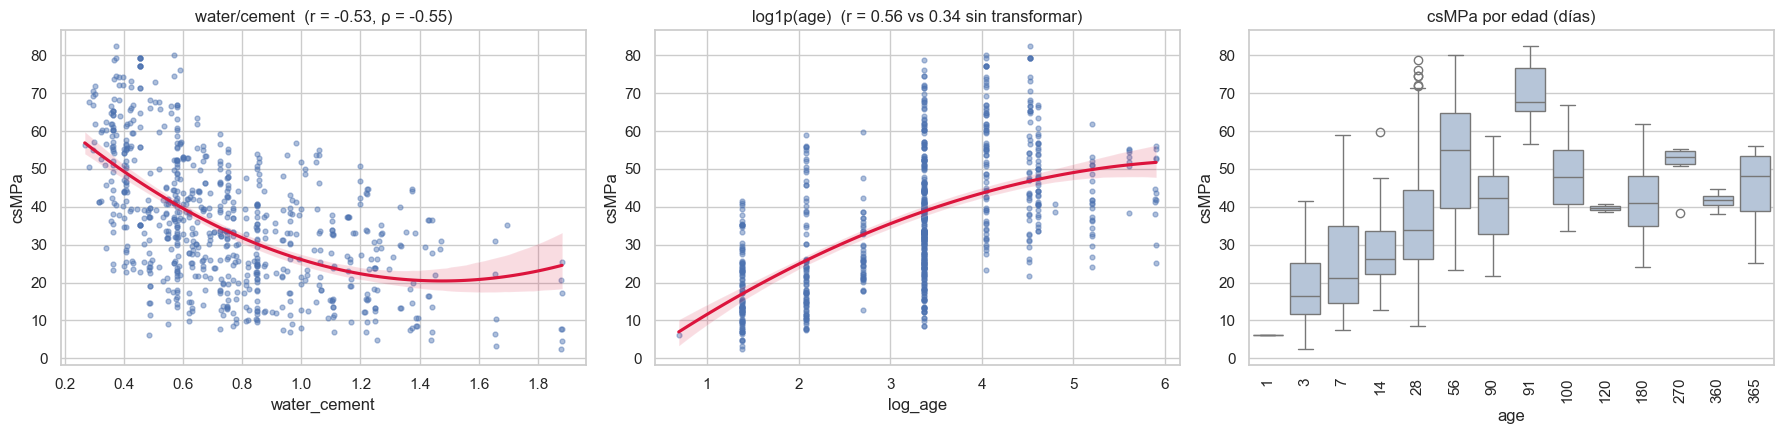

In [22]:
# Variables derivadas que motivan el feature engineering de la Parte 2.
eda = train.copy()
eda["water_cement"] = eda["water"] / eda["cement"]
eda["log_age"] = np.log1p(eda["age"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.regplot(data=eda, x="water_cement", y=TARGET, order=2, ax=axes[0],
            scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
axes[0].set_title(f"water/cement  (r = {eda['water_cement'].corr(eda[TARGET]):.2f}, "
                  f"ρ = {eda['water_cement'].corr(eda[TARGET], method='spearman'):.2f})")
sns.regplot(data=eda, x="log_age", y=TARGET, order=2, ax=axes[1],
            scatter_kws={"s": 12, "alpha": 0.45}, line_kws={"color": "crimson"})
axes[1].set_title(f"log1p(age)  (r = {eda['log_age'].corr(eda[TARGET]):.2f} vs "
                  f"{eda['age'].corr(eda[TARGET]):.2f} sin transformar)")
sns.boxplot(data=eda, x="age", y=TARGET, ax=axes[2], color="lightsteelblue")
axes[2].set_title("csMPa por edad (días)")
axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_engineered_features.png", dpi=120, bbox_inches="tight")
plt.show()

**Observaciones:**
- La **relación agua/cemento** tiene una correlación de **−0.53** con la resistencia, más fuerte que `water` (−0.30) e igual en magnitud a `cement` (+0.52), y su tendencia es claramente decreciente. Coincide con la **ley de Abrams**, el principio más conocido de la ingeniería del concreto.
- `log1p(age)` eleva la correlación lineal con el target de **0.34 a 0.56**: la resistencia crece rápido los primeros días y luego se satura, y la transformación logarítmica linealiza buena parte de esa relación.
- El boxplot por edad confirma el crecimiento de 1 a ~90 días y la meseta posterior. Hay grupos pequeños (p. ej. 120 o 360 días) con pocas mezclas, así que sus medianas reflejan qué mezclas se ensayaron más que el efecto de la edad.

### 1.8 Comparación de distribuciones entre `train` y `test`

Superponemos las densidades y aplicamos la prueba de Kolmogorov–Smirnov de dos muestras: un p-valor alto indica que no hay evidencia de que ambas muestras vengan de distribuciones distintas.

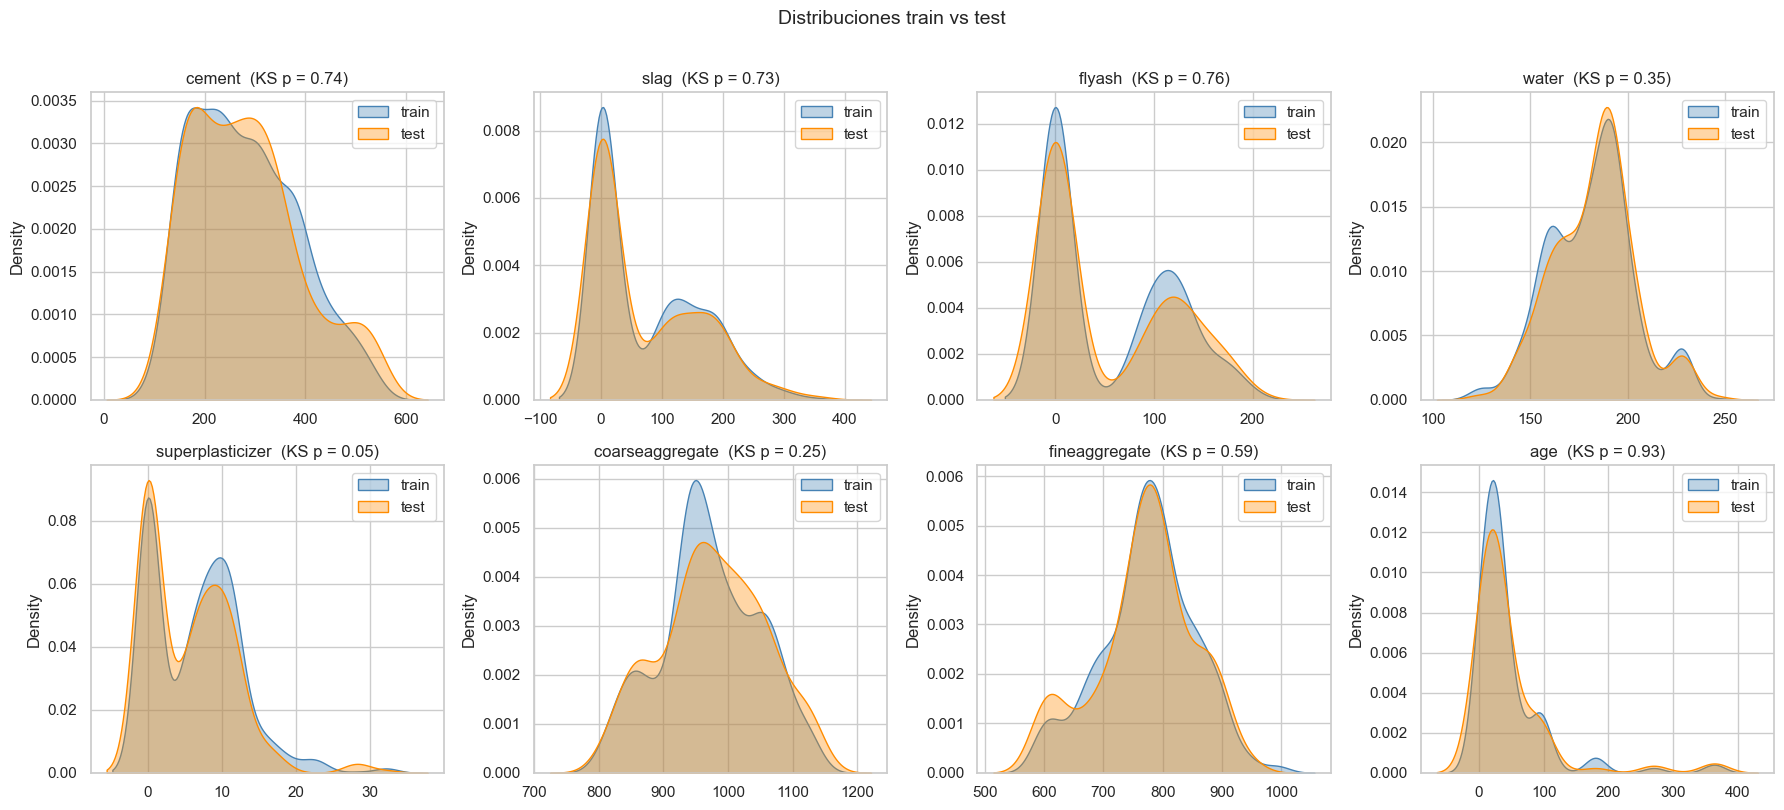

,media_train,media_test,KS_stat,p_valor
variable,,,,
cement,280.63,282.42,0.05,0.74
slag,74.74,71.93,0.05,0.73
flyash,54.87,52.59,0.04,0.76
water,181.03,182.82,0.06,0.35
superplasticizer,6.50,5.51,0.09,0.05
coarseaggregate,971.40,976.46,0.07,0.25
fineaggregate,775.13,769.97,0.05,0.59
age,44.95,47.32,0.04,0.93


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
ks_rows = []
for ax, col in zip(axes.ravel(), FEATURES):
    sns.kdeplot(train[col], ax=ax, label="train", fill=True, alpha=0.35, color="steelblue")
    sns.kdeplot(test[col], ax=ax, label="test", fill=True, alpha=0.35, color="darkorange")
    ks = stats.ks_2samp(train[col], test[col])
    ks_rows.append({"variable": col, "media_train": train[col].mean(), "media_test": test[col].mean(),
                    "KS_stat": ks.statistic, "p_valor": ks.pvalue})
    ax.set_title(f"{col}  (KS p = {ks.pvalue:.2f})")
    ax.set_xlabel("")
    ax.legend()
plt.suptitle("Distribuciones train vs test", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_train_vs_test.png", dpi=120, bbox_inches="tight")
plt.show()

pd.DataFrame(ks_rows).set_index("variable")

**Observaciones:**
- Las distribuciones de `train` y `test` son **prácticamente iguales**: las medias son muy cercanas y la prueba KS no rechaza la igualdad en 7 de las 8 variables (p entre 0.25 y 0.93).
- La excepción es `superplasticizer` (p = 0.048, apenas bajo 0.05): `test` tiene algo menos de superplastificante en promedio (5.5 vs 6.5 kg/m³). La diferencia es pequeña (KS = 0.09) y el rango es el mismo (0–32.2), así que la red no tendrá que extrapolar.
- No hay *covariate shift* relevante: lo que la red aprenda en `train` debería generalizar a `test`, y la validación interna debería ser un buen indicador del puntaje en Kaggle.

### Hallazgos del EDA y decisiones de preprocesamiento

1. **Escalas muy distintas entre predictores** (de 0–32 en `superplasticizer` a 800–1150 en `coarseaggregate`) → **escalamiento obligatorio** con `StandardScaler`, ajustado **solo con el conjunto de entrenamiento**. También estandarizaremos el target y lo des-escalaremos antes de calcular métricas.
2. **`age` muy asimétrica (skew 3.3), con 14 valores y relación no lineal y saturante con la resistencia** → usar **`log1p(age)`**, que sube la correlación con el target de 0.34 a 0.56. Se mantiene como numérica, no categórica.
3. **Muchos ceros en `slag` (45 %), `flyash` (54 %) y `superplasticizer` (35 %)** → agregar **indicadores binarios de presencia** para que la red distinga "no se usa" de "poca cantidad".
4. **La relación agua/cemento (r = −0.53) es mucho más informativa que el agua sola (r = −0.30)**, y la relación agua/material cementante (`water / (cement + slag + flyash)`) lo es aún más (r = −0.63) → *feature engineering* guiado por el dominio: `water/cement`, material cementante total (`binder`) y `water/binder`. Compararemos el desempeño con y sin estas variables.
5. **Datos limpios pero con mezclas duplicadas y ruido de laboratorio** (0 faltantes, 0 categóricas, 0 outliers en el target, 26 filas repetidas y 7 mezclas con resultados distintos), con **train y test de distribuciones casi idénticas** → no se imputa ni se codifica; se **valida con K-Fold agrupando mezclas idénticas** para evitar *leakage*. Con solo 721 filas, la red necesitará regularización y early stopping.